# Model 2 — Neural Network (MLP, PyTorch) × 3 Imbalance Strategies

**Owner**: Ayaan
**Inputs** (from Leonie's `02_data_preprocessing.ipynb`): `data/processed/train_raw.csv` (with shared `cv_fold` 0–4), `data/processed/test_raw.csv`, `data/processed/metadata.json`
**Outputs** (for Tanish): `results/mlp_A.npz`, `results/mlp_B.npz`, `results/mlp_C.npz`

| Strategy | What changes | Implementation |
|---|---|---|
| **A — Do Nothing** | Original 88.7% / 11.3% data | `BCEWithLogitsLoss()` |
| **B — Class Weighting** | Minority errors cost ~7.88× more | `BCEWithLogitsLoss(pos_weight = n_neg / n_pos)` — a true class-weighted BCE |
| **C — Resample (SMOTE)** | Training data oversampled to 1:1 | SMOTE on the training portion only, then plain `BCEWithLogitsLoss()` |

**Why PyTorch, not `sklearn.MLPClassifier`**: `MLPClassifier` has no `class_weight` and its `fit()` takes no `sample_weight`, so Strategy B could not be implemented faithfully with it.

**Architecture** (Moro et al., 2014 used an MLP): `[Linear → BatchNorm → ReLU → Dropout] × (1 or 2) → Linear(1)`, trained with Adam (+ small L2 weight decay) and early stopping.

**Leakage-free protocol**
- **Tuning**: 5-fold stratified CV on the training set with the team's shared `cv_fold` IDs, scored by **PR-AUC**. In each fold the 4 training folds are split again (90/10, stratified) into a *fit* part and an *early-stopping* part. `StandardScaler`/`OneHotEncoder` are fit on the fit part only, and SMOTE (Strategy C) is applied to the fit part only, so neither the early-stopping data nor the validation fold ever contain synthetic rows.
- **Final model**: early stopping cannot use the test set, so the number of epochs is fixed to the **median best epoch across the 5 CV folds**, and the model is retrained for that many epochs on the **full training set** (SMOTE-resampled for C). The test set is predicted exactly once.
- **Seeds**: the official export uses seed 42; the final fit is repeated with 2 more seeds to report run-to-run variability.

**Output contract (each `.npz`)**: `y_test_prob`, `y_test_pred` (threshold 0.5), `y_test`, `train_time_sec` (final training loop only), `resample_time_sec`, `n_train_samples`, `best_params` (JSON), `cv_pr_auc_mean/std`, plus out-of-fold CV probabilities `cv_oof_prob` / `cv_oof_y` for Tanish's optional threshold-tuning comparison.

In [1]:
import copy
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set DEBUG = True to run end-to-end on the 10% debug file with a tiny grid (fast).
DEBUG = False

RANDOM_STATE = 42
MODEL_NAME = "mlp"
STRATEGY_NAMES = {"A": "Do Nothing", "B": "Class Weighting", "C": "SMOTE (1:1)"}

# Hyperparameter grid (kept small: 8 configs x 5 folds x 3 strategies)
PARAM_GRID = {
    "hidden": [(64,), (128, 64)],
    "dropout": [0.2, 0.4],
    "lr": [1e-3, 3e-4],
}
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10            # epochs without early-stopping PR-AUC improvement
ES_FRACTION = 0.10       # share of each training fold held out for early stopping
FINAL_SEEDS = [42, 43, 44]

if DEBUG:
    PARAM_GRID = {"hidden": [(64,)], "dropout": [0.2], "lr": [1e-3]}
    MAX_EPOCHS, PATIENCE, FINAL_SEEDS = 30, 5, [42]

torch.set_num_threads(4)
DEVICE = torch.device("cpu")  # small tabular MLP: CPU is fast and fully deterministic

ROOT_DIR = Path(".") if Path("data/processed").exists() else Path("..")
PROC_DIR = ROOT_DIR / "data" / "processed"
RESULTS_DIR = ROOT_DIR / "results" / ("debug" if DEBUG else "")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(PROC_DIR / "metadata.json") as f:
    META = json.load(f)
NUMERIC_COLS, BINARY_COLS, CATEGORICAL_COLS = META["numeric_cols"], META["binary_cols"], META["categorical_cols"]
FEATURE_COLS = NUMERIC_COLS + BINARY_COLS + CATEGORICAL_COLS

prefix = "debug_" if DEBUG else ""
train_raw = pd.read_csv(PROC_DIR / f"{prefix}train_raw.csv")
test_raw = pd.read_csv(PROC_DIR / f"{prefix}test_raw.csv")
X_train_raw, y_train = train_raw[FEATURE_COLS], train_raw["y"].to_numpy()
X_test_raw, y_test = test_raw[FEATURE_COLS], test_raw["y"].to_numpy()
cv_folds = train_raw["cv_fold"].to_numpy()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

CONFIGS = [dict(zip(PARAM_GRID, v)) for v in itertools.product(*PARAM_GRID.values())]
print(f"Mode: {'DEBUG (10%)' if DEBUG else 'FULL'} | torch {torch.__version__}")
print(f"Train: {len(y_train):,} rows ({y_train.mean():.2%} yes) | Test: {len(y_test):,} rows ({y_test.mean():.2%} yes)")
print(f"{len(CONFIGS)} configs x {len(np.unique(cv_folds))} folds x 3 strategies | Results -> {RESULTS_DIR.resolve()}")

Mode: FULL | torch 2.15.0
Train: 32,940 rows (11.27% yes) | Test: 8,236 rows (11.27% yes)
8 configs x 5 folds x 3 strategies | Results -> /Users/ayaankukreja/Documents/Bank_Marketing/results


### Shared helpers
`build_preprocessor()` is the same `ColumnTransformer` Leonie defined (rebuilt here because `preprocessor.joblib` was pickled with scikit-learn 0.23 and does not load on newer versions; the LR notebook asserts it reproduces `processed_arrays.npz` exactly).

In [2]:
def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_COLS),
            ("bin", "passthrough", BINARY_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
        ],
        remainder="drop",
    )


def quick_metrics(y_true, y_prob, threshold=0.5):
    """Own sanity check only; Tanish's evaluation script produces the official numbers."""
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Brier": brier_score_loss(y_true, y_prob),
        "FP (wasted calls)": int(((y_pred == 1) & (y_true == 0)).sum()),
        "TP": int(((y_pred == 1) & (y_true == 1)).sum()),
    }


def save_results(strategy, y_prob, train_time_sec, resample_time_sec, n_train_samples,
                 best_params, cv_mean, cv_std, oof_prob, extra=None):
    path = RESULTS_DIR / f"{MODEL_NAME}_{strategy}.npz"
    np.savez(
        path,
        model=MODEL_NAME,
        strategy=strategy,
        strategy_name=STRATEGY_NAMES[strategy],
        y_test=y_test.astype(np.int64),
        y_test_prob=y_prob.astype(np.float64),
        y_test_pred=(y_prob >= 0.5).astype(np.int64),
        train_time_sec=float(train_time_sec),
        resample_time_sec=float(resample_time_sec),
        n_train_samples=int(n_train_samples),
        best_params=json.dumps(best_params),
        cv_pr_auc_mean=float(cv_mean),
        cv_pr_auc_std=float(cv_std),
        cv_oof_prob=oof_prob.astype(np.float64),
        cv_oof_y=y_train.astype(np.int64),
        extra=json.dumps(extra or {}),
    )
    print(f"Saved -> {path}")

### Model and training loop
- The network outputs **logits**; `BCEWithLogitsLoss` applies the sigmoid internally (numerically stable), and `pos_weight` multiplies the loss of every positive example. That is exactly the class-weighted BCE Strategy B requires.
- With early-stopping data, training stops after `PATIENCE` epochs without PR-AUC improvement and the best weights are restored. Without it (final fit), it trains for a fixed `n_epochs`.

In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)  # logits


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


@torch.no_grad()
def predict_proba(model, X):
    model.eval()
    return torch.sigmoid(model(torch.as_tensor(X, dtype=torch.float32, device=DEVICE))).cpu().numpy()


def train_mlp(X_fit, y_fit, cfg, pos_weight=None, X_es=None, y_es=None, n_epochs=None, seed=RANDOM_STATE):
    """Train one MLP. Early stopping on (X_es, y_es) PR-AUC if given, else exactly n_epochs epochs."""
    set_seed(seed)
    model = MLP(X_fit.shape[1], cfg["hidden"], cfg["dropout"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=WEIGHT_DECAY)
    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=None if pos_weight is None else torch.tensor([pos_weight], dtype=torch.float32, device=DEVICE))

    Xt = torch.tensor(np.asarray(X_fit), dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(np.asarray(y_fit), dtype=torch.float32, device=DEVICE)
    gen = torch.Generator().manual_seed(seed)
    n = len(yt)

    early_stop = X_es is not None
    epochs = MAX_EPOCHS if early_stop else n_epochs
    best_score, best_epoch, best_state, wait, history = -np.inf, epochs, None, 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            if len(idx) < 2:  # BatchNorm needs >1 sample
                continue
            opt.zero_grad()
            loss_fn(model(Xt[idx]), yt[idx]).backward()
            opt.step()

        if early_stop:
            score = average_precision_score(y_es, predict_proba(model, X_es))
            history.append(score)
            if score > best_score + 1e-4:
                best_score, best_epoch, wait = score, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= PATIENCE:
                    break

    if early_stop:
        model.load_state_dict(best_state)
    return model, best_epoch, history

### Per-fold data (computed once, reused by every config and strategy)
For each shared CV fold: 4 training folds → stratified 90/10 split into *fit* / *early-stopping* → preprocessor fit on *fit* only → SMOTE on *fit* only (for Strategy C). The validation fold is only transformed.

In [4]:
t0 = time.perf_counter()
FOLD_DATA = []
for fold in sorted(np.unique(cv_folds)):
    val = cv_folds == fold
    X_tr, y_tr = X_train_raw[~val], y_train[~val]
    fit_idx, es_idx = train_test_split(np.arange(len(y_tr)), test_size=ES_FRACTION, stratify=y_tr,
                                       random_state=RANDOM_STATE + int(fold))
    prep = build_preprocessor().fit(X_tr.iloc[fit_idx])
    d = {
        "fold": int(fold),
        "val_mask": val,
        "X_fit": prep.transform(X_tr.iloc[fit_idx]).astype(np.float32), "y_fit": y_tr[fit_idx],
        "X_es": prep.transform(X_tr.iloc[es_idx]).astype(np.float32), "y_es": y_tr[es_idx],
        "X_va": prep.transform(X_train_raw[val]).astype(np.float32), "y_va": y_train[val],
    }
    Xs, ys = SMOTE(random_state=RANDOM_STATE + int(fold)).fit_resample(d["X_fit"], d["y_fit"])
    d["X_fit_smote"], d["y_fit_smote"] = Xs.astype(np.float32), ys
    FOLD_DATA.append(d)

print(f"Prepared {len(FOLD_DATA)} folds in {time.perf_counter() - t0:.1f}s")
print(pd.DataFrame([{"fold": d["fold"], "fit": len(d["y_fit"]), "fit (SMOTE)": len(d["y_fit_smote"]),
                     "early-stop": len(d["y_es"]), "validation": len(d["y_va"]),
                     "pos_weight": round((d["y_fit"] == 0).sum() / (d["y_fit"] == 1).sum(), 3)} for d in FOLD_DATA]).to_string(index=False))

Prepared 5 folds in 1.2s
 fold   fit  fit (SMOTE)  early-stop  validation  pos_weight
    0 23716        42088        2636        6588       7.876
    1 23716        42088        2636        6588       7.876
    2 23716        42088        2636        6588       7.876
    3 23716        42088        2636        6588       7.876
    4 23716        42090        2636        6588       7.879


### Tune → refit → export (one function, run once per strategy)

In [5]:
def fold_training_data(d, strategy):
    if strategy == "C":
        return d["X_fit_smote"], d["y_fit_smote"], None
    pw = float((d["y_fit"] == 0).sum() / (d["y_fit"] == 1).sum()) if strategy == "B" else None
    return d["X_fit"], d["y_fit"], pw


def cv_evaluate(strategy, cfg):
    """5-fold CV for one config: returns per-fold PR-AUC, best epochs, OOF probs, ES curves."""
    scores, epochs, curves = [], [], []
    oof = np.zeros(len(y_train))
    for d in FOLD_DATA:
        X_fit, y_fit, pw = fold_training_data(d, strategy)
        model, best_epoch, hist = train_mlp(X_fit, y_fit, cfg, pos_weight=pw, X_es=d["X_es"], y_es=d["y_es"])
        p_va = predict_proba(model, d["X_va"])
        oof[d["val_mask"]] = p_va
        scores.append(average_precision_score(d["y_va"], p_va))
        epochs.append(best_epoch)
        curves.append(hist)
    return np.array(scores), np.array(epochs), oof, curves


CV_TABLES, SUMMARY, CURVES, SEED_RUNS = {}, {}, {}, {}

# Full training set, preprocessed once (prep fit on all training rows; test only transformed)
FINAL_PREP = build_preprocessor().fit(X_train_raw)
X_train_full = FINAL_PREP.transform(X_train_raw).astype(np.float32)
X_test_full = FINAL_PREP.transform(X_test_raw).astype(np.float32)


def run_strategy(strategy):
    print(f"=== Strategy {strategy}: {STRATEGY_NAMES[strategy]} ===")

    # 1. Grid search with leakage-free CV
    t0 = time.perf_counter()
    rows, best = [], None
    for cfg in CONFIGS:
        tc = time.perf_counter()
        scores, epochs, oof, curves = cv_evaluate(strategy, cfg)
        row = {"hidden": str(cfg["hidden"]), "dropout": cfg["dropout"], "lr": cfg["lr"],
               "cv_pr_auc_mean": scores.mean(), "cv_pr_auc_std": scores.std(),
               "median_best_epoch": int(np.median(epochs)), "sec": time.perf_counter() - tc}
        rows.append(row)
        print(f"  {row['hidden']:>9} drop={cfg['dropout']} lr={cfg['lr']:.0e} -> "
              f"PR-AUC {row['cv_pr_auc_mean']:.4f} ± {row['cv_pr_auc_std']:.4f} | epochs {row['median_best_epoch']:>3} | {row['sec']:.0f}s")
        if best is None or row["cv_pr_auc_mean"] > best["row"]["cv_pr_auc_mean"]:
            best = {"cfg": cfg, "row": row, "oof": oof, "curves": curves}
    cv_time = time.perf_counter() - t0
    cv_table = pd.DataFrame(rows).sort_values("cv_pr_auc_mean", ascending=False).reset_index(drop=True)
    CV_TABLES[strategy], CURVES[strategy] = cv_table, best["curves"]

    cfg, n_epochs = best["cfg"], max(1, best["row"]["median_best_epoch"])
    print(f"Best: {cfg} | CV PR-AUC {best['row']['cv_pr_auc_mean']:.4f} | final epochs = {n_epochs} | tuning {cv_time/60:.1f} min")

    # 2. Final training data: full training set (+ SMOTE for C)
    X_fit, y_fit, resample_time, pw = X_train_full, y_train, 0.0, None
    if strategy == "C":
        t0 = time.perf_counter()
        X_fit, y_fit = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_full, y_train)
        X_fit = X_fit.astype(np.float32)
        resample_time = time.perf_counter() - t0
    if strategy == "B":
        pw = float((y_train == 0).sum() / (y_train == 1).sum())

    # 3. Final fit for each seed (seed 42 is the official export); test predicted once per seed
    seed_rows, official = [], None
    for seed in FINAL_SEEDS:
        t0 = time.perf_counter()
        model, _, _ = train_mlp(X_fit, y_fit, cfg, pos_weight=pw, n_epochs=n_epochs, seed=seed)
        train_time = time.perf_counter() - t0
        y_prob = predict_proba(model, X_test_full)
        seed_rows.append({"seed": seed, "train_time_sec": train_time, **quick_metrics(y_test, y_prob)})
        if seed == FINAL_SEEDS[0]:
            official = (y_prob, train_time)
    SEED_RUNS[strategy] = pd.DataFrame(seed_rows)

    y_prob, train_time = official
    best_params = {"hidden": list(cfg["hidden"]), "dropout": cfg["dropout"], "lr": cfg["lr"],
                   "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE, "epochs": n_epochs,
                   "optimizer": "adam", "pos_weight": pw, "smote": strategy == "C", "seed": FINAL_SEEDS[0]}
    save_results(strategy, y_prob, train_time, resample_time, len(y_fit), best_params,
                 best["row"]["cv_pr_auc_mean"], best["row"]["cv_pr_auc_std"], best["oof"],
                 extra={"cv_time_sec": cv_time,
                        "seed_test_pr_auc": SEED_RUNS[strategy]["PR-AUC"].round(5).tolist()})

    SUMMARY[strategy] = {"Strategy": f"{strategy}: {STRATEGY_NAMES[strategy]}",
                         "Config": f"{cfg['hidden']}, d={cfg['dropout']}, lr={cfg['lr']:.0e}, ep={n_epochs}",
                         "CV PR-AUC": best["row"]["cv_pr_auc_mean"], "n_train": len(y_fit),
                         "Train time (s)": train_time, "Resample time (s)": resample_time,
                         **quick_metrics(y_test, y_prob)}
    print(f"n_train = {len(y_fit):,} ({y_fit.mean():.1%} yes) | fit {train_time:.1f}s | test PR-AUC {SUMMARY[strategy]['PR-AUC']:.4f}\n")
    return cv_table

# DO NOTHING
**Strategy A** — original class balance, unweighted BCE.

In [6]:
run_strategy("A").round(4)

=== Strategy A: Do Nothing ===


      (64,) drop=0.2 lr=1e-03 -> PR-AUC 0.4603 ± 0.0146 | epochs  16 | 12s


      (64,) drop=0.2 lr=3e-04 -> PR-AUC 0.4588 ± 0.0161 | epochs  28 | 17s


      (64,) drop=0.4 lr=1e-03 -> PR-AUC 0.4603 ± 0.0140 | epochs  22 | 12s


      (64,) drop=0.4 lr=3e-04 -> PR-AUC 0.4573 ± 0.0159 | epochs  31 | 16s


  (128, 64) drop=0.2 lr=1e-03 -> PR-AUC 0.4566 ± 0.0140 | epochs  13 | 15s


  (128, 64) drop=0.2 lr=3e-04 -> PR-AUC 0.4550 ± 0.0176 | epochs  22 | 25s


  (128, 64) drop=0.4 lr=1e-03 -> PR-AUC 0.4595 ± 0.0181 | epochs  22 | 25s


  (128, 64) drop=0.4 lr=3e-04 -> PR-AUC 0.4564 ± 0.0173 | epochs  40 | 37s
Best: {'hidden': (64,), 'dropout': 0.2, 'lr': 0.001} | CV PR-AUC 0.4603 | final epochs = 16 | tuning 2.7 min


Saved -> ../results/mlp_A.npz
n_train = 32,940 (11.3% yes) | fit 1.6s | test PR-AUC 0.4787



,hidden,dropout,lr,cv_pr_auc_mean,cv_pr_auc_std,median_best_epoch,sec
0,"(64,)",0.2,0.0010,0.4603,0.0146,16,11.9949
1,"(64,)",0.4,0.0010,0.4603,0.0140,22,12.3052
2,"(128, 64)",0.4,0.0010,0.4595,0.0181,22,25.0898
3,"(64,)",0.2,0.0003,0.4588,0.0161,28,16.7252
4,"(64,)",0.4,0.0003,0.4573,0.0159,31,16.4124
5,"(128, 64)",0.2,0.0010,0.4566,0.0140,13,15.4883
6,"(128, 64)",0.4,0.0003,0.4564,0.0173,40,36.5288
7,"(128, 64)",0.2,0.0003,0.4550,0.0176,22,25.3730


# CLASS WEIGHTING
**Strategy B** — `BCEWithLogitsLoss(pos_weight = n_neg / n_pos)` (≈ 7.88, recomputed on each training fold). Each `yes` example contributes ~7.88× more loss; the training set size is unchanged.

In [7]:
run_strategy("B").round(4)

=== Strategy B: Class Weighting ===


      (64,) drop=0.2 lr=1e-03 -> PR-AUC 0.4534 ± 0.0119 | epochs  24 | 11s


      (64,) drop=0.2 lr=3e-04 -> PR-AUC 0.4522 ± 0.0139 | epochs  41 | 17s


      (64,) drop=0.4 lr=1e-03 -> PR-AUC 0.4550 ± 0.0117 | epochs  25 | 14s


      (64,) drop=0.4 lr=3e-04 -> PR-AUC 0.4510 ± 0.0132 | epochs  31 | 16s


  (128, 64) drop=0.2 lr=1e-03 -> PR-AUC 0.4527 ± 0.0139 | epochs  17 | 19s


  (128, 64) drop=0.2 lr=3e-04 -> PR-AUC 0.4527 ± 0.0160 | epochs  27 | 23s


  (128, 64) drop=0.4 lr=1e-03 -> PR-AUC 0.4544 ± 0.0166 | epochs  22 | 21s


  (128, 64) drop=0.4 lr=3e-04 -> PR-AUC 0.4524 ± 0.0174 | epochs  17 | 31s
Best: {'hidden': (64,), 'dropout': 0.4, 'lr': 0.001} | CV PR-AUC 0.4550 | final epochs = 25 | tuning 2.5 min


Saved -> ../results/mlp_B.npz
n_train = 32,940 (11.3% yes) | fit 2.4s | test PR-AUC 0.4706



,hidden,dropout,lr,cv_pr_auc_mean,cv_pr_auc_std,median_best_epoch,sec
0,"(64,)",0.4,0.0010,0.4550,0.0117,25,13.8351
1,"(128, 64)",0.4,0.0010,0.4544,0.0166,22,21.1627
2,"(64,)",0.2,0.0010,0.4534,0.0119,24,11.1648
3,"(128, 64)",0.2,0.0003,0.4527,0.0160,27,23.3494
4,"(128, 64)",0.2,0.0010,0.4527,0.0139,17,18.8998
5,"(128, 64)",0.4,0.0003,0.4524,0.0174,17,30.6622
6,"(64,)",0.2,0.0003,0.4522,0.0139,41,16.9951
7,"(64,)",0.4,0.0003,0.4510,0.0132,31,15.7550


# RESAMPLE TRAINING DATA
**Strategy C** — SMOTE (k=5) on the standardized/encoded training data only, to a 1:1 ratio, then unweighted BCE. Early-stopping and validation data are never resampled.

> Note for the report: SMOTE interpolates one-hot columns too, so synthetic rows can have fractional categories (e.g. `job_student = 0.4`). The network treats them as continuous inputs; SMOTENC would avoid this at higher compute cost.

In [8]:
run_strategy("C").round(4)

=== Strategy C: SMOTE (1:1) ===


      (64,) drop=0.2 lr=1e-03 -> PR-AUC 0.4435 ± 0.0124 | epochs   4 | 8s


      (64,) drop=0.2 lr=3e-04 -> PR-AUC 0.4422 ± 0.0122 | epochs   9 | 12s


      (64,) drop=0.4 lr=1e-03 -> PR-AUC 0.4452 ± 0.0133 | epochs   8 | 10s


      (64,) drop=0.4 lr=3e-04 -> PR-AUC 0.4464 ± 0.0134 | epochs  13 | 15s


  (128, 64) drop=0.2 lr=1e-03 -> PR-AUC 0.4397 ± 0.0150 | epochs   2 | 15s


  (128, 64) drop=0.2 lr=3e-04 -> PR-AUC 0.4418 ± 0.0205 | epochs   4 | 17s


  (128, 64) drop=0.4 lr=1e-03 -> PR-AUC 0.4441 ± 0.0143 | epochs   3 | 15s


  (128, 64) drop=0.4 lr=3e-04 -> PR-AUC 0.4466 ± 0.0173 | epochs   7 | 22s
Best: {'hidden': (128, 64), 'dropout': 0.4, 'lr': 0.0003} | CV PR-AUC 0.4466 | final epochs = 7 | tuning 1.9 min


Saved -> ../results/mlp_C.npz
n_train = 58,458 (50.0% yes) | fit 2.3s | test PR-AUC 0.4633



,hidden,dropout,lr,cv_pr_auc_mean,cv_pr_auc_std,median_best_epoch,sec
0,"(128, 64)",0.4,0.0003,0.4466,0.0173,7,21.9576
1,"(64,)",0.4,0.0003,0.4464,0.0134,13,14.5883
2,"(64,)",0.4,0.0010,0.4452,0.0133,8,10.0617
3,"(128, 64)",0.4,0.0010,0.4441,0.0143,3,15.2525
4,"(64,)",0.2,0.0010,0.4435,0.0124,4,8.4610
5,"(64,)",0.2,0.0003,0.4422,0.0122,9,12.0138
6,"(128, 64)",0.2,0.0003,0.4418,0.0205,4,16.8449
7,"(128, 64)",0.2,0.0010,0.4397,0.0150,2,14.6845


---
# Summary
### Early-stopping curves (best config, each CV fold)

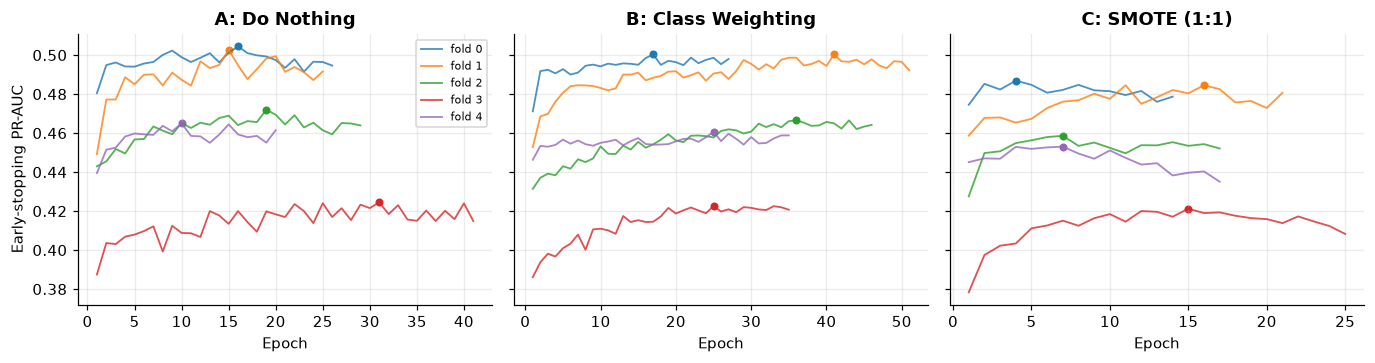

In [9]:
fig, axes = plt.subplots(1, len(CURVES), figsize=(4.2 * len(CURVES), 3.4), sharey=True, squeeze=False)
for ax, (s, curves) in zip(axes[0], CURVES.items()):
    for k, c in enumerate(curves):
        ax.plot(range(1, len(c) + 1), c, lw=1.2, alpha=0.8, label=f"fold {k}")
        ax.scatter(int(np.argmax(c)) + 1, max(c), s=18)
    ax.set_title(f"{s}: {STRATEGY_NAMES[s]}", fontweight="bold")
    ax.set_xlabel("Epoch")
axes[0][0].set_ylabel("Early-stopping PR-AUC")
axes[0][0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### Test-set sanity check (official comparison is in Tanish's evaluation)

In [10]:
pd.DataFrame(SUMMARY.values()).set_index("Strategy").round(4)

,Config,CV PR-AUC,n_train,Train time (s),Resample time (s),PR-AUC,ROC-AUC,F1,Precision,Recall,Brier,FP (wasted calls),TP
Strategy,,,,,,,,,,,,,
A: Do Nothing,"(64,), d=0.2, lr=1e-03, ep=16",0.4603,32940,1.6011,0.0000,0.4787,0.8049,0.3779,0.6329,0.2694,0.0759,145,250
B: Class Weighting,"(64,), d=0.4, lr=1e-03, ep=25",0.4550,32940,2.4068,0.0000,0.4706,0.8028,0.4751,0.3737,0.6519,0.1614,1014,605
C: SMOTE (1:1),"(128, 64), d=0.4, lr=3e-04, ep=7",0.4466,58458,2.3063,0.0489,0.4633,0.8014,0.4678,0.3584,0.6735,0.1620,1119,625


### Seed stability of the final fit (same config, different initialisation/shuffling)

In [11]:
pd.DataFrame({s: {"PR-AUC mean": r["PR-AUC"].mean(), "PR-AUC std": r["PR-AUC"].std(ddof=0),
                  "Recall mean": r["Recall"].mean(), "Precision mean": r["Precision"].mean(),
                  "Brier mean": r["Brier"].mean(), "Train time mean (s)": r["train_time_sec"].mean()}
              for s, r in SEED_RUNS.items()}).T.round(4)

,PR-AUC mean,PR-AUC std,Recall mean,Precision mean,Brier mean,Train time mean (s)
A,0.4764,0.0016,0.2518,0.6339,0.0761,1.6032
B,0.4709,0.0018,0.6566,0.3712,0.1552,2.3957
C,0.4624,0.0024,0.6656,0.3694,0.1582,2.2735


### Export check

In [12]:
for s in ["A", "B", "C"]:
    r = np.load(RESULTS_DIR / f"{MODEL_NAME}_{s}.npz")
    assert r["y_test_prob"].shape == r["y_test_pred"].shape == (len(y_test),)
    assert r["cv_oof_prob"].shape == (len(y_train),)
    print(f"{MODEL_NAME}_{s}.npz | n_train={int(r['n_train_samples']):,} | train_time={float(r['train_time_sec']):.1f}s "
          f"| best_params={r['best_params']}")

mlp_A.npz | n_train=32,940 | train_time=1.6s | best_params={"hidden": [64], "dropout": 0.2, "lr": 0.001, "weight_decay": 0.0001, "batch_size": 256, "epochs": 16, "optimizer": "adam", "pos_weight": null, "smote": false, "seed": 42}
mlp_B.npz | n_train=32,940 | train_time=2.4s | best_params={"hidden": [64], "dropout": 0.4, "lr": 0.001, "weight_decay": 0.0001, "batch_size": 256, "epochs": 25, "optimizer": "adam", "pos_weight": 7.876313662085691, "smote": false, "seed": 42}
mlp_C.npz | n_train=58,458 | train_time=2.3s | best_params={"hidden": [128, 64], "dropout": 0.4, "lr": 0.0003, "weight_decay": 0.0001, "batch_size": 256, "epochs": 7, "optimizer": "adam", "pos_weight": null, "smote": true, "seed": 42}


---
## Findings (for the report)

1. **Same story as Logistic Regression, a little stronger overall.** Test PR-AUC: A 0.479, B 0.471, C 0.463 (ROC-AUC ≈ 0.80 for all), about +0.02 over LR. Neither weighting nor SMOTE improves ranking; SMOTE is slightly worst. Across 3 seeds the PR-AUC std is only ~0.002, so the A > B > C ordering is not seed noise.
2. **Recall vs. wasted calls at threshold 0.5.**
   - A: 250 of 928 subscribers (recall 27%, precision 63%, 145 FPs).
   - B: 605 (recall 65%, precision 37%, 1,014 FPs): **+355 subscribers for +869 calls ≈ 2.4 wasted calls per extra subscriber.**
   - C: 625 (recall 67%, precision 36%, 1,119 FPs): ≈ 2.6 wasted calls per extra subscriber.
3. **Calibration cost.** Brier 0.076 (A) → 0.161 (B) / 0.162 (C): weighted/resampled probabilities are inflated well above the true ~11% rate.
4. **Compute / data cost.** B costs nothing extra in data (32,940 rows) but its best config trained longer (25 vs 16 epochs, 2.4 s vs 1.6 s). C trains on 58,458 rows (+77%) plus SMOTE time. Total tuning time was 1.9–2.7 min per strategy on CPU.
5. **SMOTE makes the network overfit almost immediately.** Early stopping picked a median of only 2–13 epochs for C (vs 13–41 for A/B), i.e. validation PR-AUC peaks early and then declines as the network memorises the interpolated synthetic positives. This is a concrete hidden cost of resampling for flexible models.
6. **Small networks suffice.** The single 64-unit hidden layer won for A and B; the 2-layer net only helped C (with heavy dropout and a lower learning rate). Differences across the grid are within ~0.005 PR-AUC.
7. Test PR-AUC is slightly higher than CV PR-AUC because the final model trains on all 32,940 rows, whereas each CV model saw only ~72% of them (4 folds minus the early-stopping split).

**Takeaway for the MLP:** class weighting is the cheaper of the two fixes and gives the same recall/precision trade-off as SMOTE with slightly better ranking. Neither beats doing nothing on PR-AUC, so (as with LR) Tanish's threshold-tuning comparison is the key test of whether either is worth it.